In [14]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib import patches


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/exploration/../../../../utils/train_utils.py'>

In [3]:
read_ids = list(range(0, 12+1))
# read_ids = [0,   # paper
# 			2,
# 			3,
# 			4,
# 			5,
# 			6,
# 			8,
# 			9]   # good
# read_ids = [0]
plot_id = 0

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
# prep

# def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
#     return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)
#
# sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]
#
# traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
#
# markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [6]:
selection_bhl = ['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move']

plot_idx = file_ids.index(plot_id)

In [69]:
print([np.sum(np.sum(state.values, axis=1) == 1).item() for state in states])
print([state.values.shape[0] for state in states])

[10009, 18745, 7581, 5519, 15956, 18590, 14252, 12373, 11201, 8286, 18548, 15314, 8913]
[10219, 19083, 7671, 5598, 16206, 19095, 14355, 12657, 11408, 8533, 19089, 15871, 9438]


In [70]:
state_frequencies = [{state_label: np.sum(state[state_label].values) / np.sum(np.sum(state.values, axis=1) == 1) for state_label in state.columns} for state in states]

In [71]:
print([np.sum(np.array([state_frequencies[i][label] for label in state_frequencies[i].keys()])) for i in range(len(filenames))])

[np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(0.9999999999999999), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]


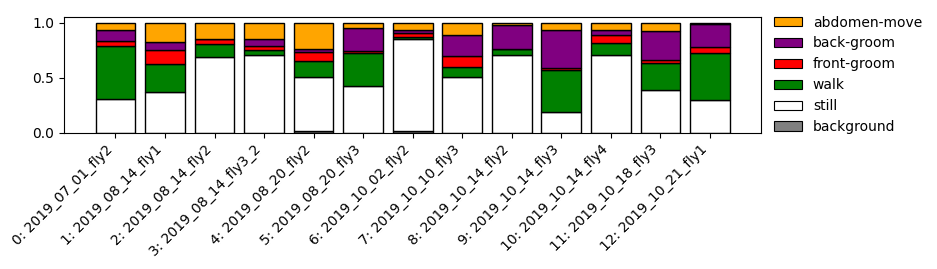

In [85]:
state_labels_ordered = ['background', 'still', 'walk', 'front-groom', 'back-groom', 'abdomen-move']
state_label_to_color = {'background': 'gray',
						'still': 'white',
						'walk': 'green',
						'front-groom': 'red',
						'back-groom': 'purple',
						'abdomen-move': 'orange'}

plt.figure(figsize=(9, 1.5))
for file_idx in range(len(filenames)):
	state_label = state_labels_ordered[0]

	bottom = 0
	plt.bar([f'{file_idx}: {filenames[file_idx]}'], state_frequencies[file_idx][state_label], bottom=bottom,
			color=state_label_to_color[state_label], label=state_label, edgecolor='black', linewidth=1)

	for i in range(1, len(state_labels_ordered)):
		state_label = state_labels_ordered[i]
		state_label_previous = state_labels_ordered[i-1]

		state_frequency = state_frequencies[file_idx][state_label]
		state_frequency_previous = state_frequencies[file_idx][state_label_previous]

		bottom += state_frequency_previous
		plt.bar([f'{file_idx}: {filenames[file_idx]}'], state_frequency, bottom=bottom,
				color=state_label_to_color[state_label], label=state_label, edgecolor='black', linewidth=1)

plt.xticks(rotation=45, ha='right')
legend = plt.legend(
	handles=[patches.Patch(color=state_label_to_color[state_label], label=state_label) for state_label in state_labels_ordered[::-1]],
    loc='center left',
    bbox_to_anchor=(1, 0.5),
	frameon=False
)
for handle in legend.legend_handles:
    handle.set_edgecolor('black')
    handle.set_linewidth(0.8)